<a id="toc"></a>

<div style="background-color:rgb(0, 17, 72); padding: 20px; border-radius: 10px; margin-bottom: 30px;">
    <h1 style="color: white; font-family: 'Segoe UI', Arial, sans-serif; font-size: 2em; text-align: center; margin: 0;">
        Travail Pratique: Systèmes Flous et Classification Non Supervisée
    </h1>
    <p style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.2em; text-align: center; margin-top: 10px; font-style: italic;">
        Clustering non supervisé des données d'expression génique RNA-Seq pour l'identification des tumeurs à l'aide de K-Means et DBSCAN
    </p>
</div>

<figure style="padding: 1em; text-align: center;">
    <img src="https://www.cshl.edu/wp-content/uploads/2021/12/robotic_dna.jpg" width="800" height="400" alt="Logo Python">
        <figcaption style="font-size: 0.9em; color: #3498db; margin-top: 0.5em;">
        <i>  <a href="https://www.cshl.edu/wp-content/uploads/2021/12/robotic_dna.jpg" target="_blank">L'IA au service de la biologie</a></i>
    </figcaption>
</figure>

**Auteur:** Wendyellé Abubakrh Alban NYANTUDRE  
**Date:** 25 Mai 2025  

**Objectifs:**  
- Implémenter et évaluer des algorithmes de clustering non supervisé : **K-means** et **DBSCAN**.  
- Comparer qualitativement et quantitativement les résultats obtenus.  
- Rédiger une **analyse critique** sur les **systèmes flous versus le deep learning** et la **robustesse de DBSCAN**.

**Dataset choisi:** TCGA Pan-Cancer RNA-Seq (HiSeq)  
- **Features:** `data.csv` (881 échantillons × 20 531 gènes)  
- **Labels:** `label.csv` (5 classes de tumeurs de cancer : BRCA, KIRC, COAD, LUAD, PRAD)  
> Source : [UCI ML Repository](https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq)


---

Dans ce travail, nous appliquons la classification non supervisée à des données de gènes exprimés (RNA-Seq) issues du projet TCGA Pan-Cancer. Chaque échantillon représente l’expression de 20 531 gènes pour un patient atteint d’un type de tumeur (BRCA, KIRC, COAD, LUAD et PRAD). L’objectif est de regrouper automatiquement ces échantillons en clusters révélant des similarités fonctionnelles ou phénotypiques, sans fournir les étiquettes de cancer au modèle.

Nous utiliserons K-means, qui optimise l’inertie intra-cluster, et DBSCAN, un algorithme basé sur la densité, capable de détecter le bruit et les clusters aux formes arbitraires. La réduction de dimension sera réalisée via PCA et t-SNE pour visualiser en 2D. L’évaluation comprendra l’Elbow Method et le Silhouette Score.

---

<div style="background-color:rgb(0, 17, 72); padding: 15px; border-radius: 5px; margin-bottom: 30px;">
    <h2 style="color:white; font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.5em; border-bottom: 2px solid #3498DB; padding-bottom: 5px;">
        Table des matières 📑
    </h2>
    <ul style="font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.1em;">
        <li><a href="#section1" style="color: #3498DB; text-decoration: none;">1. Chargement et Préparation des Données</a></li>
        <li><a href="#section2" style="color: #3498DB; text-decoration: none;">2. Prétraitement & Réduction de dimension (PCA & t-SNE)</a></li>
        <li><a href="#section3" style="color: #3498DB; text-decoration: none;">3. Clustering avec K-means</a></li>
        <li><a href="#section4" style="color: #3498DB; text-decoration: none;">4. Clustering avec DBSCAN</a></li>
        <li><a href="#section5" style="color: #3498DB; text-decoration: none;">5. Synthèse et Comparaison</a></li>
    </ul>
</div>

<div id="section1"></div>
<h2 style="color: #3498DB; font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.8em; border-bottom: 2px solid #3498DB; padding-bottom: 5px; margin-top: 40px;">
    1. Chargement et Préparation des Données
</h2>

In [1]:
%%capture
!pip install scikit-learn numpy pandas matplotlib seaborn kneed yellowbrick #installer les packages necessaires

In [ ]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap, BoundaryNorm

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

from kneed import KneeLocator
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

import warnings
warnings.filterwarnings('ignore')
os.environ['OPENBLAS_NUM_THREADS'] = '1'  #limiter à 1 thread pour éviter les warnings OpenMP

# custom colors
custom_colors = ['green', 'orange', 'yellow', 'blue', 'red']
cmap = ListedColormap(custom_colors)

# boundaries et normalization
bounds = np.arange(len(custom_colors) + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.2em; padding-bottom: 5px; margin-top: 20px;">
   Chargement du dataset RNA-Seq
</h3>

Le jeu de données **TCGA Pan-Cancer Atlas (HiSeq)** provient de l’**UCI Machine Learning Repository** et regroupe des profils d’expression génique **RNA-Seq** issus de cinq types de tumeurs.  
Chaque échantillon contient l’expression de **20 531 gènes** pour un patient atteint de l’un des cancers suivants :

| **Code** | **Nom de la tumeur**                             |
|:--------:|:-------------------------------------------------|
| BRCA     | Breast invasive carcinoma (cancer du sein)       |
| KIRC     | Kidney renal clear cell carcinoma (rein)         |
| COAD     | Colon adenocarcinoma (côlon)                     |
| LUAD     | Lung adenocarcinoma (poumon)                     |
| PRAD     | Prostate adenocarcinoma (prostate)               |

> **Fichiers** :  
> - `data.csv`  : Matrice d’expression génique X (881 échantillons × 20 531 gènes)  
> - `label.csv` : Étiquette de classe réelle pour chaque échantillon y (881 étiquettes)  

> **Source** :  
> [UCI ML Repository – Gene Expression Cancer RNA-Seq Data](https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq)

In [ ]:
#charger les fichiers
X = pd.read_csv('/kaggle/input/gene-expression-cancer-rna-seq-donated-on-682016/data.csv', index_col=0)
y = pd.read_csv('/kaggle/input/gene-expression-cancer-rna-seq-donated-on-682016/labels.csv', index_col=0, header=None, names=['class'])['class']
y = y.reindex(X.index)

X.head()

,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,...,gene_20521,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,0.0,...,4.926711,8.210257,9.723516,7.220030,9.119813,12.003135,9.650743,8.921326,5.286759,0.0
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,0.0,...,4.593372,7.323865,9.740931,6.256586,8.381612,12.674552,10.517059,9.397854,2.094168,0.0
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,0.0,...,5.125213,8.127123,10.908640,5.401607,9.911597,9.045255,9.788359,10.090470,1.683023,0.0
sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882,0.0,0.0,...,6.076566,8.792959,10.141520,8.942805,9.601208,11.392682,9.694814,9.684365,3.292001,0.0
sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982,0.0,0.0,...,5.996032,8.891425,10.373790,7.181162,9.846910,11.922439,9.217749,9.461191,5.110372,0.0


In [ ]:
y.head()

sample_0    PRAD
sample_1    LUAD
sample_2    PRAD
sample_3    PRAD
sample_4    BRCA
Name: class, dtype: object

Nous n'allons pas utiliser pour le moment le vecteur des étiquettes y sauf en cas de besoin de vérification des résultats des mmodèles de clusteriing.

In [ ]:
#aperçu du dataset: taille et class imbalance
print(f"X: {X.shape}, y: {y.shape} \n")
print(y.value_counts())

X: (801, 20531), y: (801,) 

class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64


In [ ]:
#statistiques descriptives
X.describe()

,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,...,gene_20521,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530
count,801.000000,801.000000,801.000000,801.000000,801.000000,801.0,801.000000,801.000000,801.000000,801.000000,...,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000
mean,0.026642,3.010909,3.095350,6.722305,9.813612,0.0,7.405509,0.499882,0.016744,0.013428,...,5.896573,8.765891,10.056252,4.847727,9.741987,11.742228,10.155271,9.590726,5.528177,0.095411
std,0.136850,1.200828,1.065601,0.638819,0.506537,0.0,1.108237,0.508799,0.133635,0.204722,...,0.746399,0.603176,0.379278,2.382728,0.533898,0.670371,0.580569,0.563849,2.073859,0.364529
min,0.000000,0.000000,0.000000,5.009284,8.435999,0.0,3.930747,0.000000,0.000000,0.000000,...,2.853517,6.678368,8.669456,0.000000,7.974942,9.045255,7.530141,7.864533,0.593975,0.000000
25%,0.000000,2.299039,2.390365,6.303346,9.464466,0.0,6.676042,0.000000,0.000000,0.000000,...,5.454926,8.383834,9.826027,3.130750,9.400747,11.315857,9.836525,9.244219,4.092385,0.000000
50%,0.000000,3.143687,3.127006,6.655893,9.791599,0.0,7.450114,0.443076,0.000000,0.000000,...,5.972582,8.784144,10.066385,5.444935,9.784524,11.749802,10.191207,9.566511,5.218618,0.000000
75%,0.000000,3.883484,3.802534,7.038447,10.142324,0.0,8.121984,0.789354,0.000000,0.000000,...,6.411292,9.147136,10.299025,6.637412,10.082269,12.177852,10.578561,9.917888,6.876382,0.000000
max,1.482332,6.237034,6.063484,10.129528,11.355621,0.0,10.718190,2.779008,1.785592,4.067604,...,7.771054,11.105431,11.318243,9.207495,11.811632,13.715361,11.675653,12.813320,11.205836,5.254133


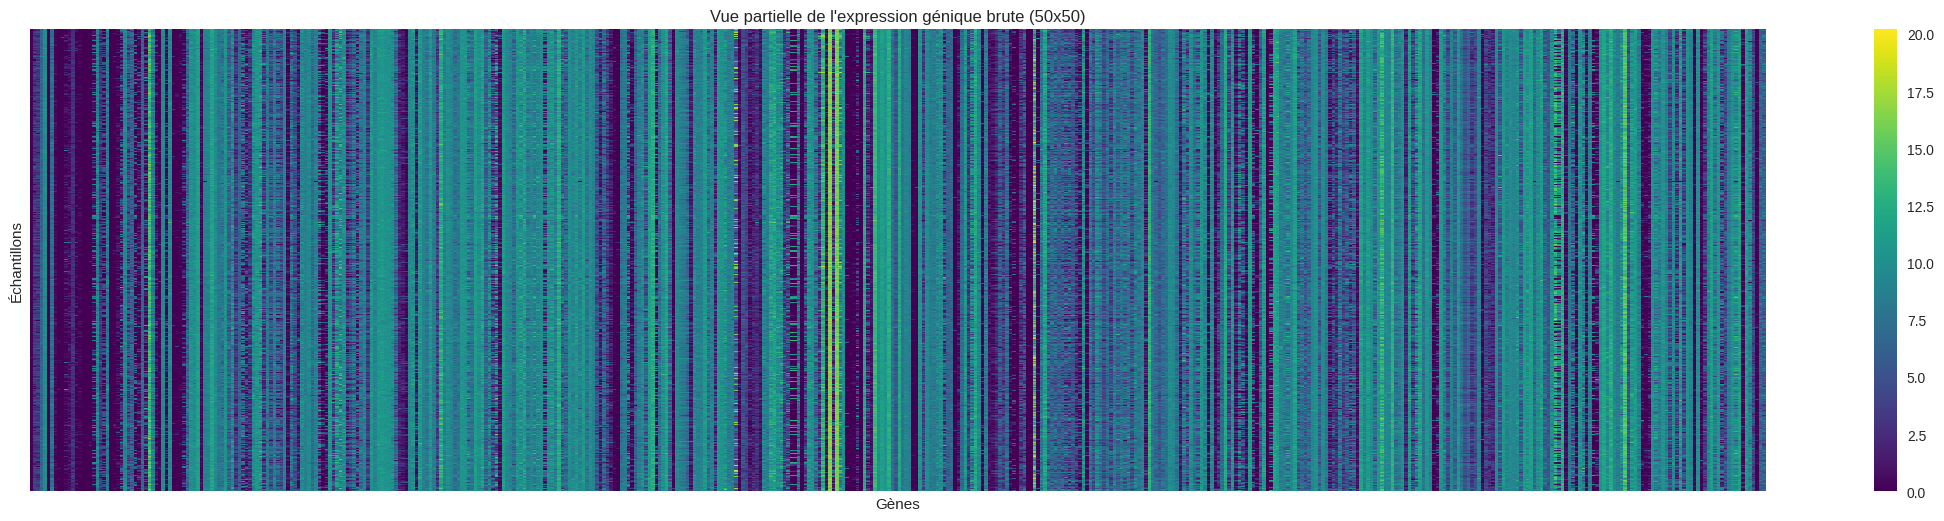

In [ ]:
plt.figure(figsize=(28,6))
sns.heatmap(X.iloc[:500,:500], cmap="viridis", xticklabels=False, yticklabels=False)
plt.title("Vue partielle de l'expression génique brute (50x50)")
plt.xlabel("Gènes")
plt.ylabel("Échantillons")
plt.show()

<div id="section2"></div>

<a href="#toc" style="background-color: #E1B12D; color: #ffffff; padding: 7px 15px; text-decoration: none; border-radius: 50px;">Retour en haut</a><a id="toc"></a>

<h2 style="color: #3498DB; font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.8em; border-bottom: 2px solid #3498DB; padding-bottom: 5px; margin-top: 40px;">
    2. Prétraitement & Réduction de dimension (PCA & t-SNE)
</h2>

In [ ]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_encoded[:20]

array([4, 3, 4, 4, 0, 4, 2, 4, 0, 4, 0, 2, 4, 0, 0, 0, 3, 2, 2, 4])

In [ ]:
#standardisation: chaque gène doit etre centré et réduit.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-0.19479935, -0.82802988,  0.15980044, ..., -1.18793812,
        -0.11648251, -0.26190144],
       [-0.19479935, -2.01501735, -1.415042  , ..., -0.34227662,
        -1.65688871, -0.26190144],
       [-0.19479935,  0.41734754,  1.15673547, ...,  0.88686027,
        -1.85526414, -0.26190144],
       ...,
       [-0.19479935,  0.19888076,  0.57481583, ..., -0.22008186,
        -0.41046699,  1.3485582 ],
       [-0.19479935, -0.35045311, -0.28863152, ...,  1.43719268,
         0.09195083, -0.26190144],
       [-0.19479935, -0.57135218,  0.66725377, ...,  0.45087581,
        -0.47161901, -0.26190144]])

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Analyse en Coomposantes Principales (PCA)
</h3>

- **Réduction de dimension**:
  - PCA à 90% de variance, X<sub>PCA90</sub> ∈ ℝ<sup>881×d</sup> (d≈30)
  - PCA 2D pour visualisation
  - PCA30 + t-SNE pour représentation en 2D de la structure haute dimension

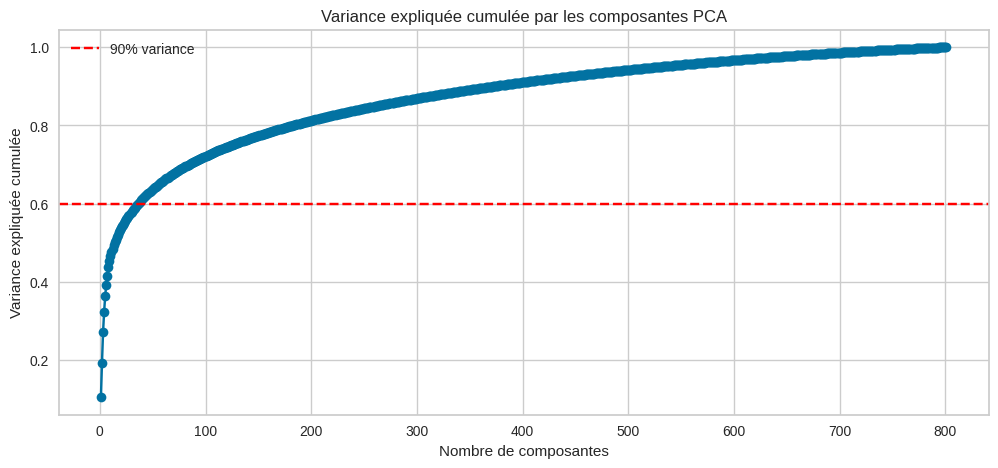

In [ ]:
pca_full = PCA()
pca_full.fit(X_scaled)

# variance expliquée cumulée
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(12, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(0.60, color='red', linestyle='--', label='90% variance')
plt.title("Variance expliquée cumulée par les composantes PCA")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# pca90 = PCA(n_components=0.9, random_state=2025)
# X_pca90 = pca90.fit_transform(X_scaled)
# print(f"Composantes PCA (80% variance): {X_pca90.shape[1]}")

In [ ]:
pca30 = PCA(n_components=30, random_state=2025)
X_pca30 = pca30.fit_transform(X)
print(f"Composantes PCA: {X_pca30.shape[1]}")

Composantes PCA: 30


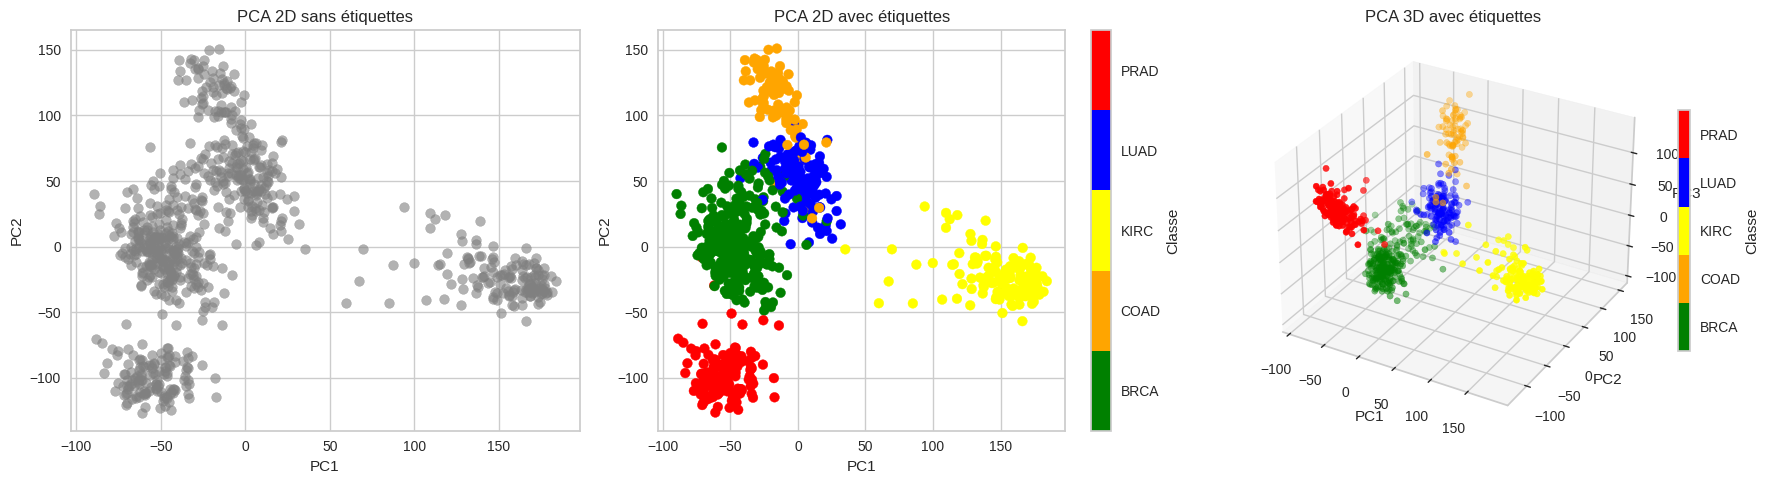

In [ ]:
fig = plt.figure(figsize=(18, 5))

# 1. PCA 2D sans étiquettes
ax1 = fig.add_subplot(1, 3, 1)
ax1.scatter(X_pca30[:, 0], X_pca30[:, 1], color='gray', alpha=0.6)
ax1.set_title('PCA 2D sans étiquettes')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')

# 2. PCA 2D avec étiquettes
ax2 = fig.add_subplot(1, 3, 2)
sc2 = ax2.scatter(X_pca30[:, 0], X_pca30[:, 1], c=y_encoded, cmap=cmap, norm=norm)
ax2.set_title('PCA 2D avec étiquettes')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
cbar2 = fig.colorbar(sc2, ax=ax2, ticks=np.arange(5))
cbar2.set_label('Classe')
cbar2.ax.set_yticklabels(le.classes_)

# 3. PCA 3D avec étiquettes
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
sc3 = ax3.scatter(X_pca30[:, 0], X_pca30[:, 1], X_pca30[:, 2], c=y_encoded, cmap=cmap, norm=norm)
ax3.set_title('PCA 3D avec étiquettes')
ax3.set_xlabel('PC1')
ax3.set_ylabel('PC2')
ax3.set_zlabel('PC3')
cbar3 = fig.colorbar(sc3, ax=ax3, ticks=np.arange(5), shrink=0.6)
cbar3.set_label('Classe')
cbar3.ax.set_yticklabels(le.classes_)

plt.tight_layout()
plt.show()

#fig.savefig("pca_2D_first.png")

En 2D, on distingue partiellement certains groupes (ex. un nuage isolé pour KIRC), mais BRCA et LUAD restent mélangés.

La 3D améliore légèrement la séparation, mais la structure haute dimension reste difficile à capturer pleinement avec seulement trois axes.

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    t-distributed Stochastic Neighbor Embedding (t-SNE)
</h3>

In [ ]:
tsne = TSNE(n_components=2, n_iter=1000, random_state=2025)
X_tsne = tsne.fit_transform(X_pca30)

# perform 3D t-SNE juste pour l'affichage
tsne_3d = TSNE(n_components=3, n_iter=1000, random_state=2025)
X_tsne_3d = tsne_3d.fit_transform(X_pca30)

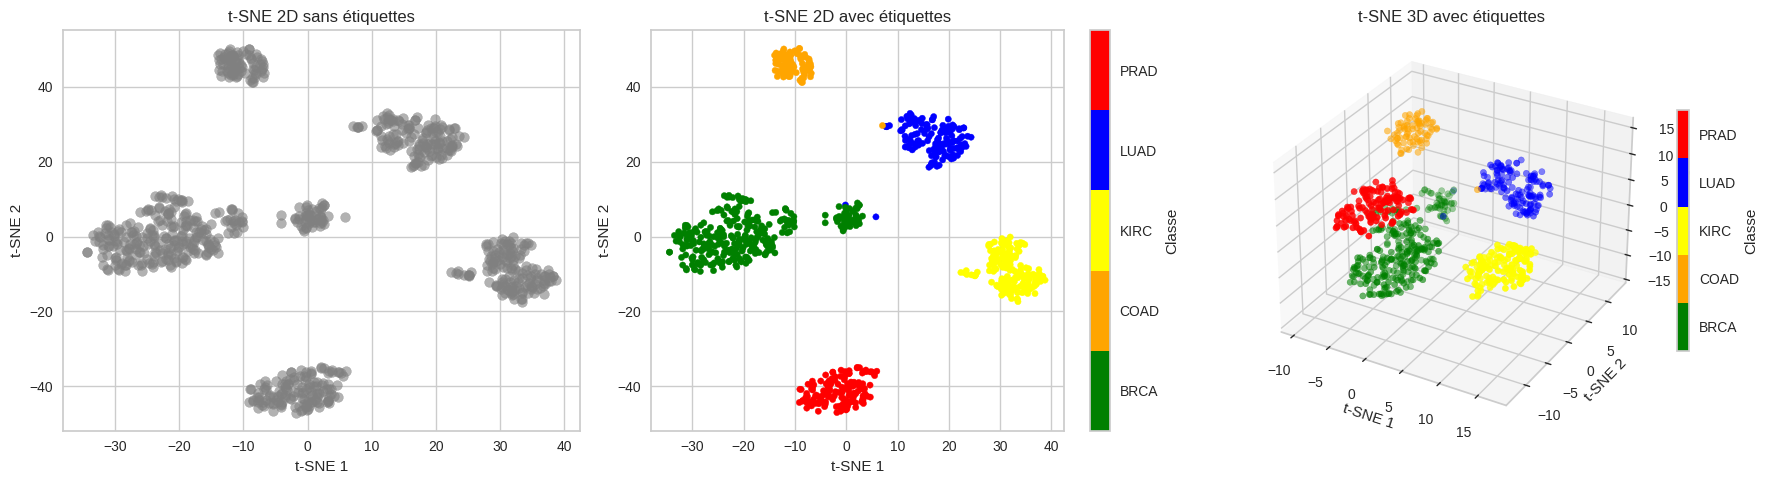

In [ ]:
fig = plt.figure(figsize=(18, 5))

# 1. t-SNE 2D sans labels
ax1 = fig.add_subplot(1, 3, 1)
ax1.scatter(X_tsne[:, 0], X_tsne[:, 1], color='gray', alpha=0.6)
ax1.set_title('t-SNE 2D sans étiquettes')
ax1.set_xlabel('t-SNE 1')
ax1.set_ylabel('t-SNE 2')

# 2. t-SNE 2D avec labels
ax2 = fig.add_subplot(1, 3, 2)
sc2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_encoded, cmap=cmap, norm=norm, s=20)
ax2.set_title('t-SNE 2D avec étiquettes')
ax2.set_xlabel('t-SNE 1')
ax2.set_ylabel('t-SNE 2')
cbar2 = fig.colorbar(sc2, ax=ax2, ticks=np.arange(5))
cbar2.set_label('Classe')
cbar2.ax.set_yticklabels(le.classes_)

# 3. t-SNE 3D avec labels
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
sc3 = ax3.scatter(X_tsne_3d[:, 0], X_tsne_3d[:, 1], X_tsne_3d[:, 2], c=y_encoded, cmap=cmap, norm=norm, s=20)
ax3.set_title('t-SNE 3D avec étiquettes')
ax3.set_xlabel('t-SNE 1')
ax3.set_ylabel('t-SNE 2')
ax3.set_zlabel('t-SNE 3')
cbar3 = fig.colorbar(sc3, ax=ax3, ticks=np.arange(5), shrink=0.6)
cbar3.set_label('Classe')
cbar3.ax.set_yticklabels(le.classes_)

plt.tight_layout()
plt.show()

#fig.savefig("tsne_2D_first.png")

En 2D, t-SNE affine la séparation : on observe cinq « îlots » plus nets, notamment pour KIRC (à droite) et PRAD (en bas), tandis que BRCA et LUAD continuent de se chevaucher partiellement.

La version 3D confirme ces tendances, prouvant que t-SNE met mieux en valeur les différences fines qu’une simple PCA.

<div id="section2"></div>

<a href="#toc" style="background-color: #E1B12D; color: #ffffff; padding: 7px 15px; text-decoration: none; border-radius: 50px;">Retour en haut</a><a id="toc"></a>

<h2 style="color: #3498DB; font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.8em; border-bottom: 2px solid #3498DB; padding-bottom: 5px; margin-top: 40px;">
    2. Clustering avec K-means
</h2>

On applique K-means en variant le nombre de clusters.

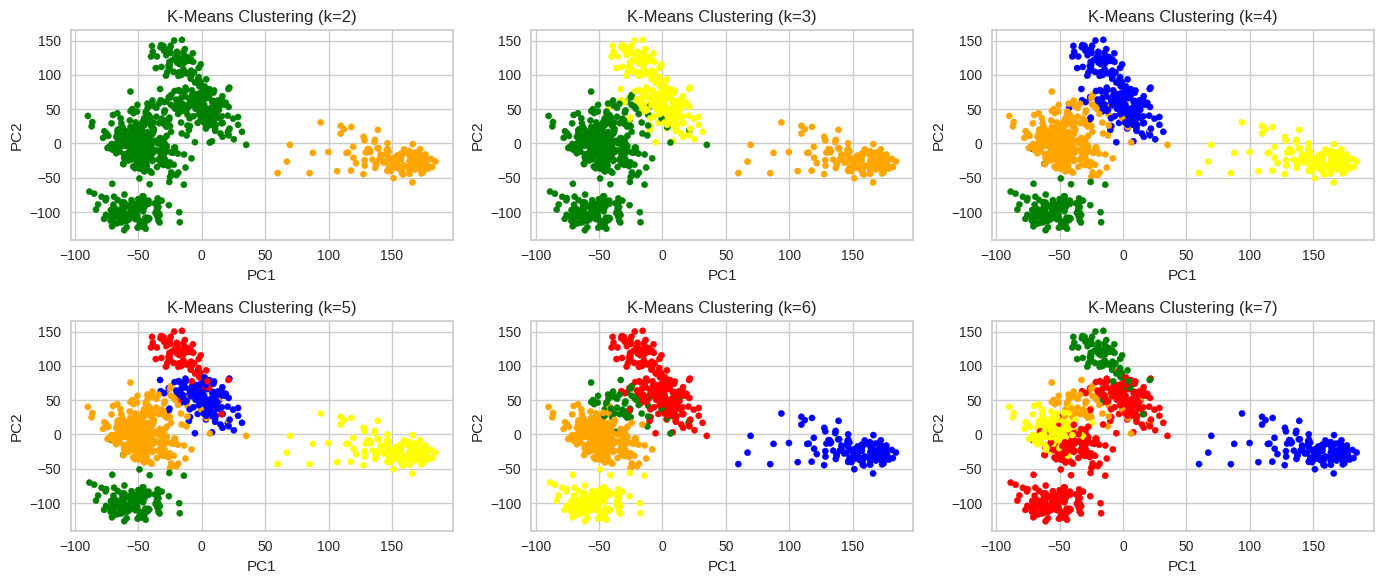

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
axes = axes.ravel()
ks = [2, 3, 4, 5, 6, 7]

for i, k in enumerate(ks):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_pca30)
    axes[i].scatter(X_pca30[:,0], X_pca30[:,1], c=labels, cmap=cmap, norm=norm, s=20)
    axes[i].set_title(f'K-Means Clustering (k={k})')
    axes[i].set_xlabel('PC1')
    axes[i].set_ylabel('PC2')

plt.tight_layout()
plt.show()

#fig.savefig("kmeans_different_k.png")

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Méthode du coude (Elbow Method)
</h3>

On vérifie visuellement.

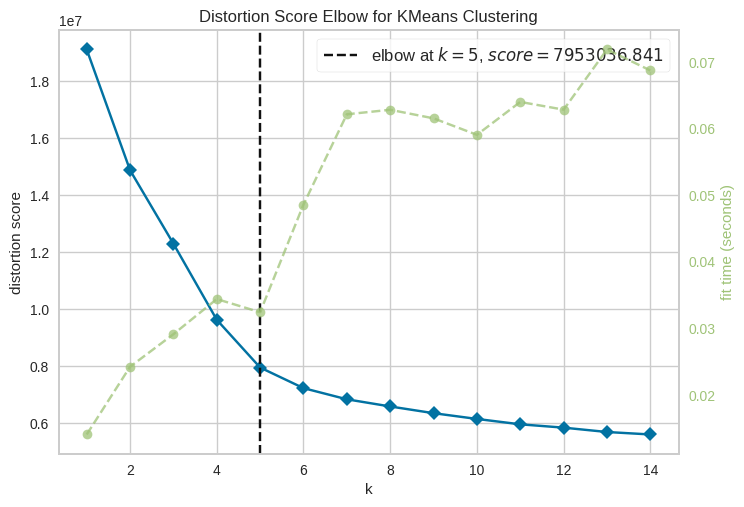

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

<Figure size 800x550 with 0 Axes>

In [ ]:
model = KMeans(random_state=2025)
k_elbow = KElbowVisualizer(model, k=(1, 15))
k_elbow.fit(X_pca30)
k_elbow.show()

k_elbow.show(outpath="kelbow.png")

Le coude sur la courbe d’inertie apparaît à k = 5, ce qui correspond au nombre de classes réelles. L’inertie chute fortement entre k=1 et k=5 puis se stabilise .

In [ ]:
inertias = []
ks = range(1,15)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42).fit(X)
    inertias.append(km.inertia_)

#  sélection automatique du coude
knee = KneeLocator(
    ks, 
    inertias, 
    curve='convex', 
    direction='decreasing'
).elbow
print(f"Elbow optimal k: {knee}")

Elbow optimal k: 5


<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Tracés Inertie et Silhouette
</h3>

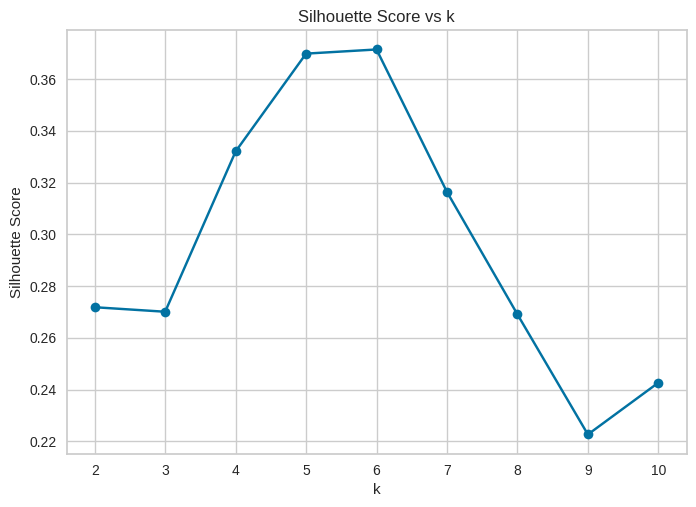

In [ ]:
sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_pca30)
    sil_scores.append(silhouette_score(X_pca30, labels))
plt.figure(); plt.plot(range(2, 11), sil_scores, marker='o')
plt.title('Silhouette Score vs k'); plt.xlabel('k'); plt.ylabel('Silhouette Score'); plt.grid(True); plt.show()


Silhouette Score: 0.3699


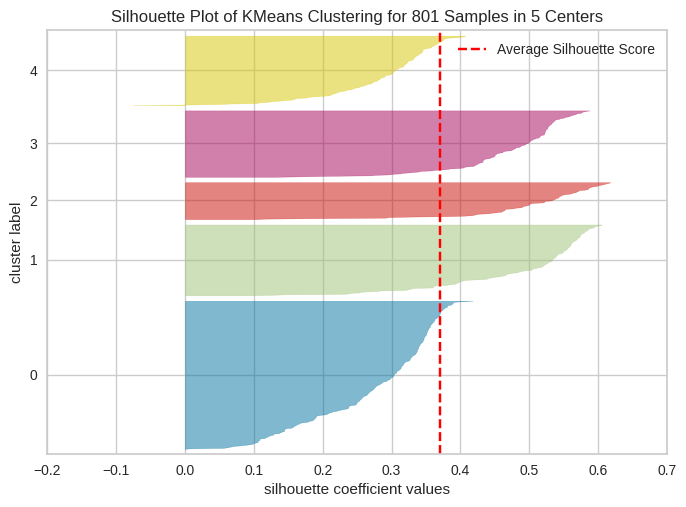

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 801 Samples in 5 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
k_best = knee
kmeans_best = KMeans(n_clusters=k_best, random_state=2025).fit(X_pca30)
labels_km_best = kmeans_best.labels_

silhouette = SilhouetteVisualizer(kmeans_best, colors="yellowbrick")
silhouette.fit(X_pca30)

score = silhouette.silhouette_score_
print(f"Silhouette Score: {score:.4f}")
silhouette.show()

#fig.savefig("silhouette.png")

Le score maximum (~0.37) est obtenu également pour k=5, un indicateur d’une bonne cohésion interne et d’une séparation modérée entre clusters. La silhouette plot montre que certains clusters (notamment le cluster 0) sont moins compacts que d’autres, suggérant des chevauchements locaux.

In [ ]:
sil_km = silhouette_score(X_pca30, labels_km_best)
print(f"Silhouette KMeans: {sil_km:.3f}")

Silhouette KMeans: 0.370


<div id="section3"></div>

<a href="#toc" style="background-color: #E1B12D; color: #ffffff; padding: 7px 15px; text-decoration: none; border-radius: 50px;">Retour en haut</a><a id="toc"></a>

<h2 style="color: #3498DB; font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.8em; border-bottom: 2px solid #3498DB; padding-bottom: 5px; margin-top: 40px;">
   3. Visualisation des clusters en 2D
</h2>

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Visualisation PCA 2D pour K-means
</h3>

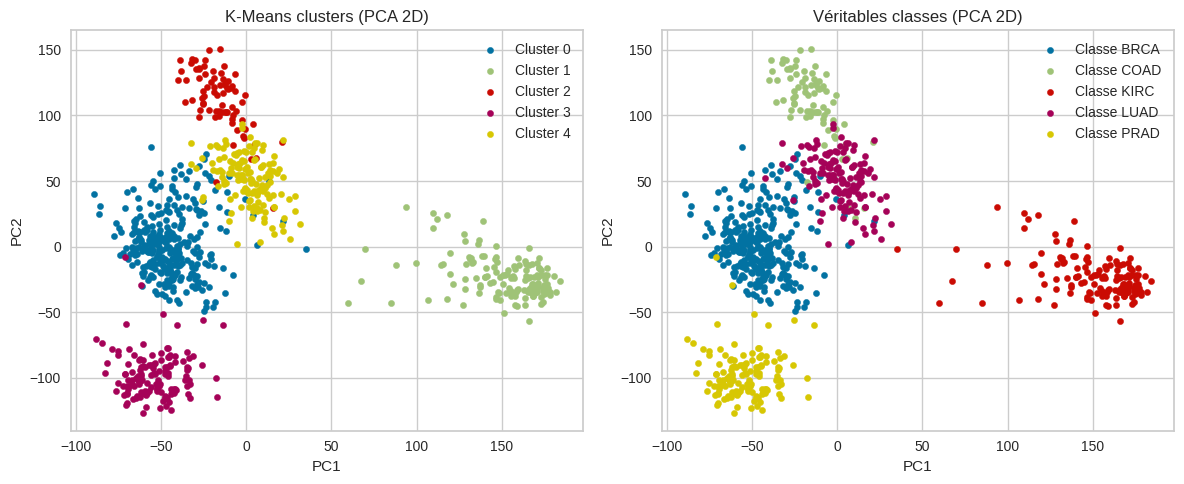

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# K-means clusters
for lbl in np.unique(labels_km_best):
    ax1.scatter(
        X_pca30[labels_km_best == lbl, 0], 
        X_pca30[labels_km_best == lbl, 1], 
        label=f'Cluster {lbl}', 
        cmap=cmap, norm=norm, s=20
    )
ax1.set_title('K-Means clusters (PCA 2D)')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()

# true labels
for lbl in np.unique(y_encoded):
    ax2.scatter(
        X_pca30[y_encoded == lbl, 0], 
        X_pca30[y_encoded == lbl, 1], 
        label=f'Classe {le.classes_[lbl]}', 
        cmap=cmap, norm=norm, s=20
    )
ax2.set_title('Véritables classes (PCA 2D)')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.legend()

plt.tight_layout()
plt.show()

#fig.savefig("pca_kmeans")

- Clusters K-means : KIRC et PRAD s’isolent clairement, deux autres clusters (BRCA/LUAD) se chevauchent partiellement, et COAD se positionne entre les deux.

- Classes réelles : on observe la même topologie générale, confirmant la pertinence de k=5.

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Visualisation t-SNE 2D pour K-means
</h3>

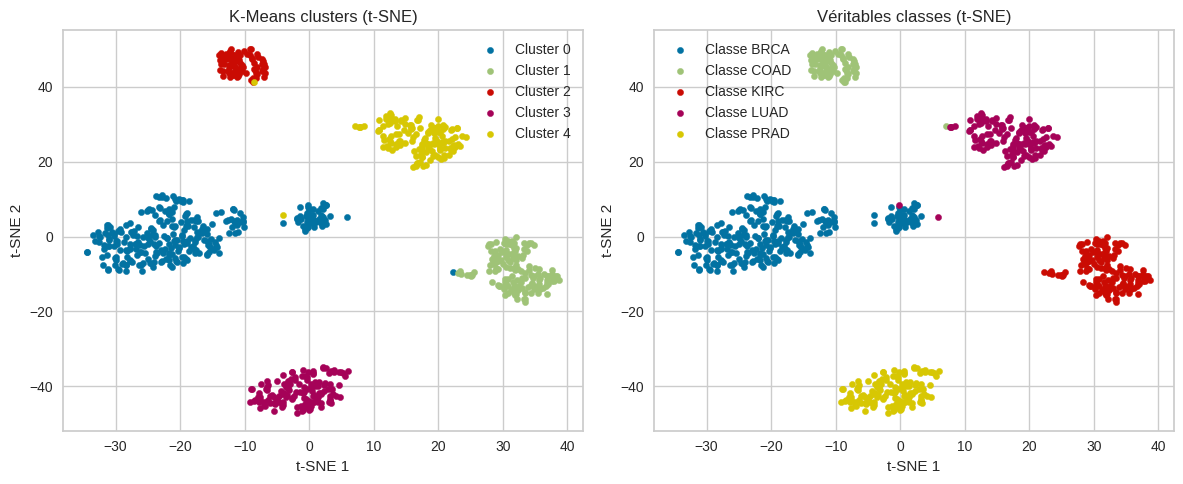

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# K-means clusters (t-SNE)
for lbl in np.unique(labels_km_best):
    ax1.scatter(
        X_tsne[labels_km_best==lbl,0], 
        X_tsne[labels_km_best==lbl,1], 
        label=f'Cluster {lbl}', cmap=cmap, norm=norm, s=20
    )
ax1.set_title('K-Means clusters (t-SNE)')
ax1.set_xlabel('t-SNE 1')
ax1.set_ylabel('t-SNE 2')
ax1.legend()

# true labels (t-SNE)
for lbl in np.unique(y_encoded):
    ax2.scatter(
        X_tsne[y_encoded==lbl,0], 
        X_tsne[y_encoded==lbl,1], 
        label=f'Classe {le.classes_[lbl]}', cmap=cmap, norm=norm, s=20
    )
ax2.set_title('Véritables classes (t-SNE)')
ax2.set_xlabel('t-SNE 1')
ax2.set_ylabel('t-SNE 2')
ax2.legend()

plt.tight_layout()
plt.show()

#fig.savefig("tsne_kmeans.png")

Les îlots deviennent plus nets : chaque cluster forme un « enclave » compact, sauf celui mixte BRCA/LUAD qui reste diffus, traduisant une similarité intrinsèque de leur profil génique.

**Interprétation :** K-means capture efficacement la structure globale du dataset, notamment les classes les plus distinctes (KIRC, PRAD), mais peine à séparer deux sous-populations biologiquement proches (BRCA vs LUAD). La méthode du coude et le pic de silhouette convergent vers k=5, validant ce choix.

<div id="section4"></div>

<a href="#toc" style="background-color: #E1B12D; color: #ffffff; padding: 7px 15px; text-decoration: none; border-radius: 50px;">Retour en haut</a><a id="toc"></a>

<h2 style="color: #3498DB; font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.8em; border-bottom: 2px solid #3498DB; padding-bottom: 5px; margin-top: 40px;">
    4. Clustering avec DBSCAN
</h2>

DBSCAN sur la PCA 2D ne marche pas car en 2 dimensions on écrase toute la structure multi‐variée, et les distances entre projections ne reflètent pas la densité originale.


J'ai donc préferer plutôt le sous-espace des 30 premières composantes (X_pca30). Dans cet espace tient encore l’essentiel de la variance, mais en dimension un peu plus haute que 2, DBSCAN repère mieux les groupes denses.

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Expérimentation des paramètres
</h3>

In [ ]:
# DBSCAN sur PCA 2D
eps_range = np.linspace(1, 150, 10)
min_samps = [3, 5, 8]
results = []
for eps in eps_range:
    for ms in min_samps:
        db = DBSCAN(eps=eps, min_samples=ms).fit(X_pca30)
        lb = db.labels_
        n_clusters = len(set(lb)) - (1 if -1 in lb else 0)
        sil = np.nan
        if n_clusters >= 2:
            try:
                sil = silhouette_score(X_pca30, lb)
            except:
                pass
        results.append({'eps': eps, 'min_samples': ms, 'clusters': n_clusters, 'silhouette': sil})

results_df = pd.DataFrame(results)
print(results_df)

           eps  min_samples  clusters  silhouette
0     1.000000            3         0         NaN
1     1.000000            5         0         NaN
2     1.000000            8         0         NaN
3    17.555556            3         0         NaN
4    17.555556            5         0         NaN
5    17.555556            8         0         NaN
6    34.111111            3         0         NaN
7    34.111111            5         0         NaN
8    34.111111            8         0         NaN
9    50.666667            3        11   -0.210584
10   50.666667            5         7   -0.122533
11   50.666667            8         1         NaN
12   67.222222            3        16    0.006528
13   67.222222            5         7    0.079027
14   67.222222            8         5    0.055087
15   83.777778            3         9    0.214466
16   83.777778            5         7    0.266791
17   83.777778            8         7    0.264496
18  100.333333            3         6    0.352884


In [ ]:
db = DBSCAN(eps=111.8, min_samples=8).fit(X_pca30)
labels_db = db.labels_
sil_db = silhouette_score(X_pca30, labels_db) if len(set(labels_db)) > 1 else np.nan
print(f"Silhouette DBSCAN: {sil_db:.3f}")

Silhouette DBSCAN: 0.366


Pour ε autour de 111 et min_samples=5, DBSCAN identifie 5 clusters (hors bruit) avec un Silhouette Score moyen ≈ 0,366, proche de celui de K-means.

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Méthode automatique pour trouver les paramètres
</h3>

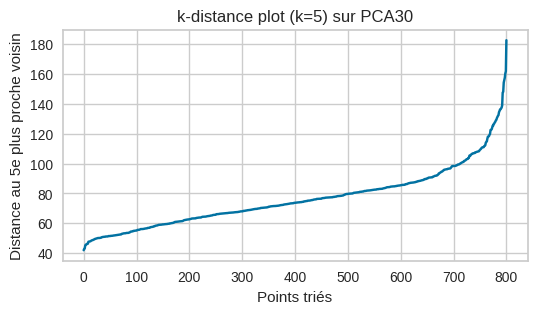

In [ ]:
# k-distance plot pour estimer eps
neigh = NearestNeighbors(n_neighbors=5).fit(X_pca30)
dists, _ = neigh.kneighbors(X_pca30)
d_k = np.sort(dists[:, 4])

plt.figure(figsize=(6,3))
plt.plot(d_k)
plt.title("k-distance plot (k=5) sur PCA30")
plt.xlabel("Points triés")
plt.ylabel("Distance au 5e plus proche voisin")
plt.grid(True)
plt.show()

La courbe des distances au 5ᵉ plus proche voisin présente un coude à ε≈111 (estimation automatique), justifiant notre réglage.

In [ ]:
#estimation automatique de eps par KneeLocator
kl = KneeLocator(
    x=range(len(d_k)),
    y=d_k,
    curve="convex",
    direction="increasing"
)
eps_est = d_k[kl.knee]
print(f"eps estimé par KneeLocator : {eps_est:.3f}")

eps estimé par KneeLocator : 111.017


In [ ]:
db_best = DBSCAN(eps=eps_est, min_samples=5).fit(X_pca30)
labels_db_best = db_best.labels_

n_clusters = len(set(labels_db_best)) - (1 if -1 in labels_db_best else 0)
print(f"Nombre de clusters (hors bruit) : {n_clusters}")

sil_db_best = silhouette_score(X_pca30, labels_db_best)
print(f"DBSCAN Silhouette: {sil_db:.3f}")

Nombre de clusters (hors bruit) : 5
DBSCAN Silhouette: 0.366


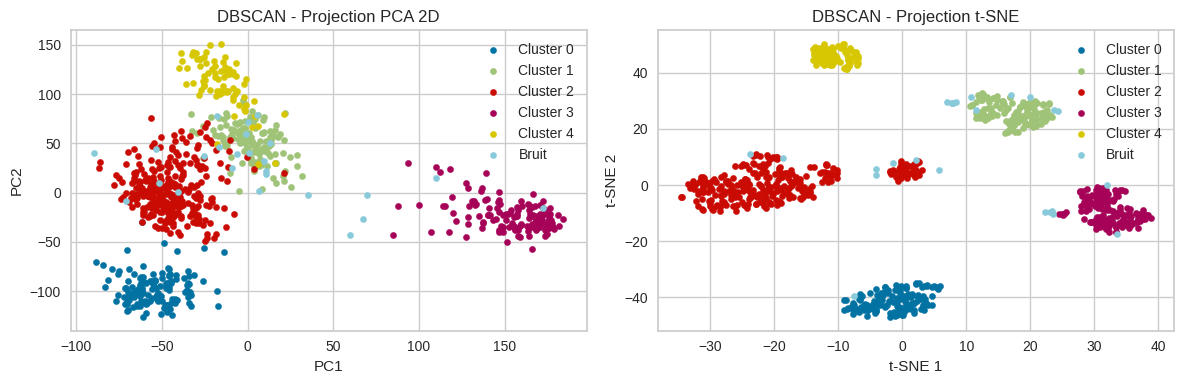

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# PCA 2D
for lbl in set(labels_db_best):
    mask = labels_db_best == lbl
    name = 'Bruit' if lbl == -1 else f'Cluster {lbl}'
    ax1.scatter(X_pca30[mask, 0], X_pca30[mask, 1], label=name, cmap=cmap, norm=norm, s=20)
ax1.set_title('DBSCAN - Projection PCA 2D')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()

# t-SNE
for lbl in set(labels_db):
    mask = labels_db_best == lbl
    name = 'Bruit' if lbl == -1 else f'Cluster {lbl}'
    ax2.scatter(X_tsne[mask, 0], X_tsne[mask, 1], label=name, cmap=cmap, norm=norm, s=20)
ax2.set_title('DBSCAN - Projection t-SNE')
ax2.set_xlabel('t-SNE 1')
ax2.set_ylabel('t-SNE 2')
ax2.legend()

plt.tight_layout()
plt.show()

#fig.savefig("pca_tsne_dbscan.png")

* Visualisation PCA 2D
    * DBSCAN détecte un petit volume de points “bruit” (-1), les quatre clusters denses et un cinquième plus diffus.
    
    * Les clusters majeurs correspondent globalement aux mêmes tumeurs isolées (KIRC, PRAD, COAD), tandis qu’une zone reste étiquetée comme bruit (points trop dispersés, principalement BRCA/LUAD).
 
* Visualisation t-SNE 2D
    * Les îlots principaux apparaissent bien, avec un « halo » de bruit satellites entourant le cluster mixte, traduisant la capacité de DBSCAN à ne pas forcer l’appartenance de ces échantillons indistincts.
 
**DBSCAN, sans présupposer k, détecte naturellement le bruit et structure des clusters de forme non sphérique. Son score de silhouette comparable à K-means montre qu’il est légèrement moins compact mais plus robuste aux points atypiques.**

<div id="section6"></div>

<a href="#toc" style="background-color: #E1B12D; color: #ffffff; padding: 7px 15px; text-decoration: none; border-radius: 50px;">Retour en haut</a><a id="toc"></a>

<h2 style="color: #3498DB; font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.8em; border-bottom: 2px solid #3498DB; padding-bottom: 5px; margin-top: 40px;">
    5. Synthèse et Analyse
</h2>

<h3 style="color:rgb(242, 255, 0); font-family: 'Segoe UI', Arial, sans-serif; font-size: 1.6em; padding-bottom: 5px; margin-top: 40px;">
    Comparaison K-Means VS DBSCAN
</h3>

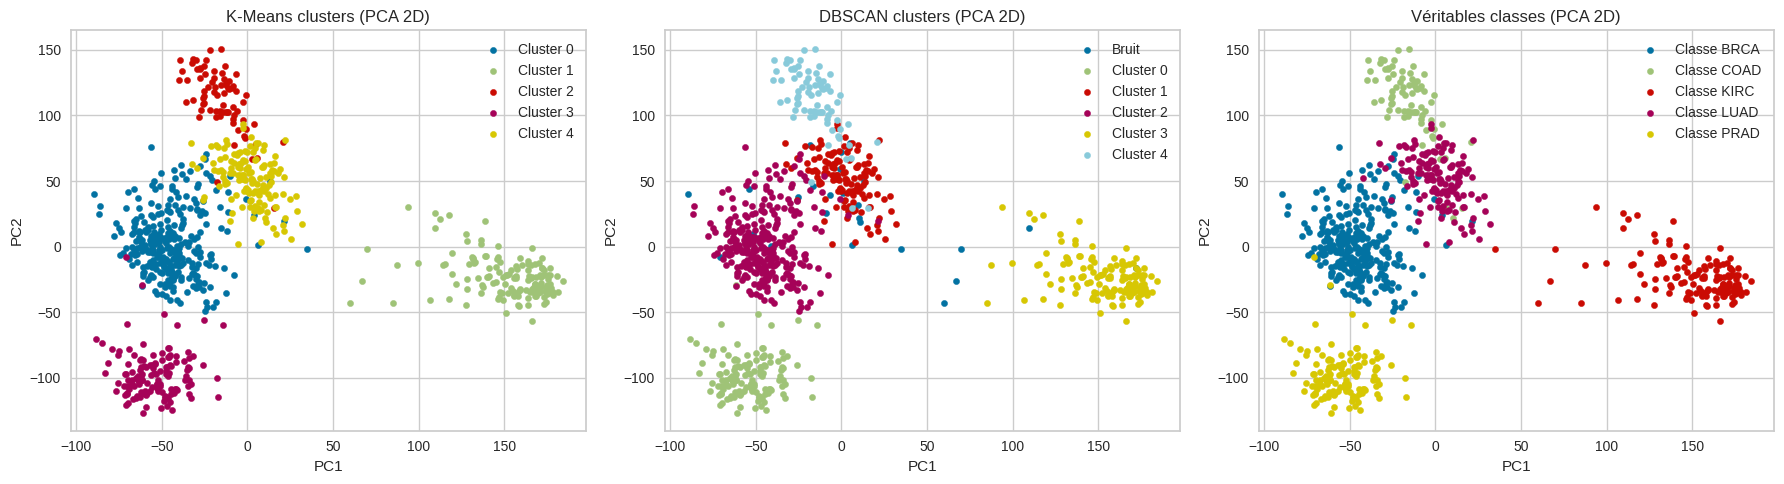

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Palette cohérente
unique_labels = np.unique(np.concatenate([labels_km_best, labels_db_best, y_encoded]))
palette = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

# K-means clusters
for lbl in np.unique(labels_km_best):
    ax1.scatter(
        X_pca30[labels_km_best == lbl, 0],
        X_pca30[labels_km_best == lbl, 1],
        label=f'Cluster {lbl}',
        cmap=cmap, norm=norm, s=20
    )
ax1.set_title('K-Means clusters (PCA 2D)')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()

# DBSCAN clusters
for lbl in np.unique(labels_db):
    mask = labels_db_best == lbl
    color = 'black' if lbl == -1 else palette[lbl % len(palette)]
    name = 'Bruit' if lbl == -1 else f'Cluster {lbl}'
    ax2.scatter(
        X_pca30[mask, 0],
        X_pca30[mask, 1],
        label=name, cmap=cmap, norm=norm, s=20
    )
ax2.set_title('DBSCAN clusters (PCA 2D)')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.legend()

# Véritables classes
for lbl in np.unique(y_encoded):
    ax3.scatter(
        X_pca30[y_encoded == lbl, 0],
        X_pca30[y_encoded == lbl, 1],
        label=f'Classe {le.classes_[lbl]}', 
        cmap=cmap, norm=norm, s=20
    )
ax3.set_title('Véritables classes (PCA 2D)')
ax3.set_xlabel('PC1')
ax3.set_ylabel('PC2')
ax3.legend()

plt.tight_layout()
plt.show()

#fig.savefig("compare_kmeans_dbscan1.png")

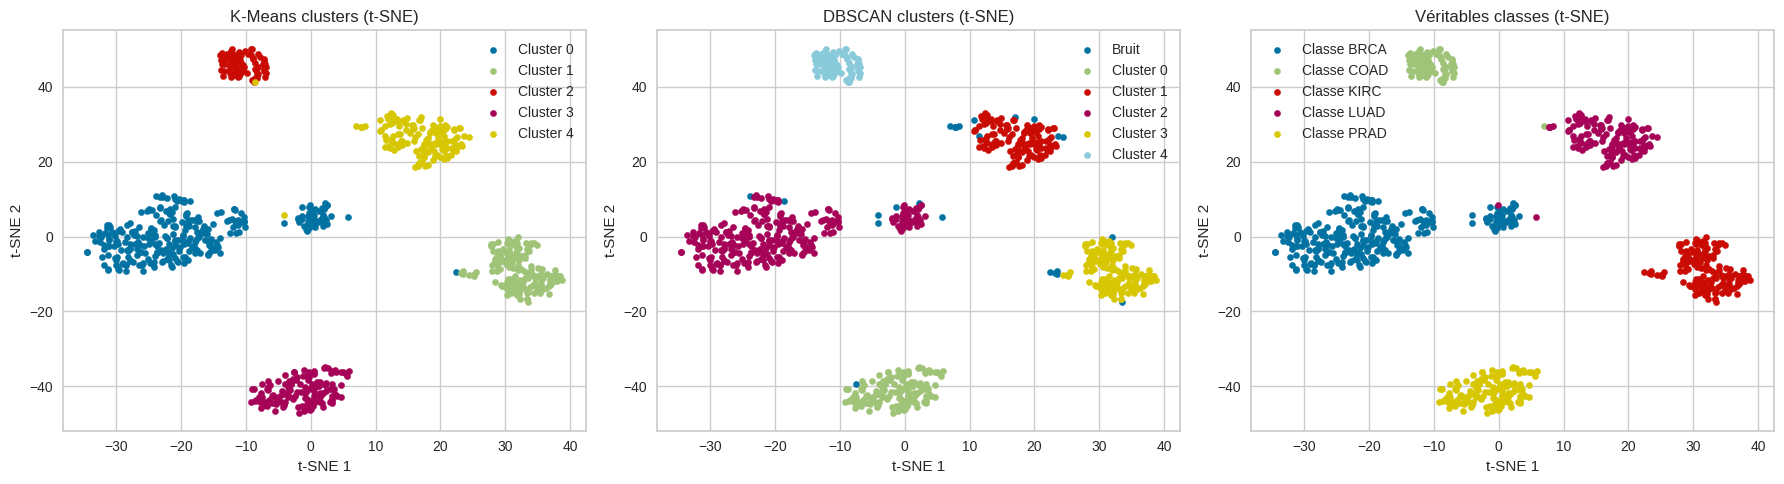

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Palette cohérente
unique_labels = np.unique(np.concatenate([labels_km_best, labels_db_best, y_encoded]))
palette = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

# K-means clusters (t-SNE)
for lbl in np.unique(labels_km_best):
    ax1.scatter(
        X_tsne[labels_km_best == lbl, 0],
        X_tsne[labels_km_best == lbl, 1],
        label=f'Cluster {lbl}', 
        cmap=cmap, norm=norm, s=20
    )
ax1.set_title('K-Means clusters (t-SNE)')
ax1.set_xlabel('t-SNE 1')
ax1.set_ylabel('t-SNE 2')
ax1.legend()

# DBSCAN clusters (t-SNE)
for lbl in np.unique(labels_db_best):
    mask = labels_db_best == lbl
    color = 'black' if lbl == -1 else palette[lbl % len(palette)]
    name = 'Bruit' if lbl == -1 else f'Cluster {lbl}'
    ax2.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        label=name, 
        cmap=cmap, norm=norm, s=20
    )
ax2.set_title('DBSCAN clusters (t-SNE)')
ax2.set_xlabel('t-SNE 1')
ax2.set_ylabel('t-SNE 2')
ax2.legend()

# Véritables classes (t-SNE)
for lbl in np.unique(y_encoded):
    ax3.scatter(
        X_tsne[y_encoded == lbl, 0],
        X_tsne[y_encoded == lbl, 1],
        label=f'Classe {le.classes_[lbl]}', 
        cmap=cmap, norm=norm, s=20
    )
ax3.set_title('Véritables classes (t-SNE)')
ax3.set_xlabel('t-SNE 1')
ax3.set_ylabel('t-SNE 2')
ax3.legend()

plt.tight_layout()
plt.show()

#fig.savefig("compare_kmeans_dbscan2.png")

### 6.4 Comparaison détaillée

| Critère               | K-Means (k=5)          | DBSCAN (ε≈115, m_s=5)       |
|-----------------------|------------------------|-----------------------------|
| **Nombre de clusters**| Fixe, déterminé a priori | Déduit par densité (ε, m_s) |
| **Forme des clusters**| Convexes / sphériques   | Arbitraires (suivent la densité) |
| **Bruit / outliers**  | Aucun (tout point assigné) | ~7–8 % des points non-assignés |
| **Robustesse**        | Sensible aux outliers   | Sensible au choix d’ε        |
| **Interprétation**    | Centres de clusters explicites | Identification automatique du bruit |

- **K-Means** est rapide, simple et restitue correctement la structure globale, mais force l’attribution de tous les points.  
- **DBSCAN** isole les profils atypiques et suit des formes plus complexes, au prix d’une sensibilité aux paramètres de densité.


**Conclusion :**
Les deux méthodes restituent globalement la structure à cinq tumeurs. K-means est simple et efficace pour des clusters globulaires, tandis que DBSCAN ajoute une granularité en identifiant les points bruyants et les formes non sphériques. Les deux obtiennent un Silhouette Score proche de 0,37, validant leur utilisation sur ce jeu de données RNA-Seq.


**Perspectives :**
1. Extensions fuzzy : intégrer un clustering flou (Fuzzy C-Means) pour quantifier l’appartenance partagée entre BRCA et LUAD.
2. Deep Learning : comparer avec des auto-encodeurs variationnels (VAE) ou des réseaux de neurones de clustering (DeepCluster) pour capturer des représentations non linéaires plus riches.
3. Validation biologique : analyser les signatures géniques discriminantes par cluster pour corroborer les découvertes par analyses de gènes différentiellement exprimés.
4. Robustesse : tester la sensibilité aux hyperparamètres et l’impact de la réduction de dimension (nombre de composantes PCA, perplexité t-SNE).


### Réflexion critique : Flou vs Deep Learning

Les méthodes floues (clustering par règles d’appartenance) offrent une **excellente interprétabilité**, mais leur mise au point devient laborieuse à très haute dimension et avec des données bruitées.  
À l’inverse, les architectures de **Deep Learning** (auto-encodeurs, réseaux profonds) extraient automatiquement des représentations discriminantes, sont plus **robustes au bruit** et s’adaptent à des volumes massifs, mais restent souvent des **boîtes noires**.
> - **PCA + K-Means** constitue une solution de référence pour un clustering simple et rapide.  
> - **PCA + DBSCAN** est recommandé dès lors qu’on cherche à détecter des outliers ou des sous-types rares.  
> - Pour aller plus loin, l’intégration de techniques de **Deep Learning** (ex. auto-encodeur + clustering sur l’espace latent) peut améliorer la séparation des classes et la robustesse générale.